# Chapitre 9 - Cours 3 : validation atomique et transactions distribuées (2PC)

Ce notebook couvre la partie *Atomic Commit and Two-Phase Commit (2PC)* de la section
*Distributed Transactions and Consensus* (*From single-node to distributed atomic
commit*, *Introduction to two-phase commit*, *A system of promises*, *Coordinator
failure*, *Three-phase commit*) et la partie *Distributed Transactions in Practice*
(*Exactly-once message processing*, *XA transactions*, *Holding locks while in doubt*,
*Recovering from coordinator failure*, *Limitations of distributed transactions*). Les
transactions sur un seul nœud (ACID, isolation) ont été étudiées au chapitre
7 ; le consensus tolérant aux pannes, qui permet de dépasser les limites
de 2PC, est l'objet du cours suivant.

**Plan.**

1. De la validation locale à la validation distribuée.
2. Le protocole de validation à deux phases.
3. Un système de promesses : 2PC face aux pannes.
4. La panne du coordinateur : participants en doute.
5. Pourquoi ne pas décider seul ? (validation à trois phases).
6. Transactions distribuées hétérogènes et XA.
7. Verrous tenus en doute et reprise après panne.
8. Les limites des transactions XA.

Le protocole est simulé sur le simulateur à événements discrets `ddia.sim` (réseau
asynchrone, pannes de nœuds), avec les classes `Coordinator2PC` et `Participant2PC` de
[`ddia/transactions.py`](../../ddia/transactions.py) ; la fonction `run_2pc` lance une
transaction et renvoie la trace des messages et une synthèse par participant.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import run_2pc, Participant2PC
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)

COULEUR_MSG = {"begin": SLATE, "prepare": INDIGO, "vote": VIOLET, "commit": GREEN, "abort": ROSE,
               "ack": GRAY, "status?": AMBER, "status": AMBER, "commit1": GREEN}


def frise(run, title, subtitle=None, t_max=None, width=11, labels=True):
    """Diagramme espace-temps d'une exécution de run_2pc : messages, verrous (bande
    sarcelle), période en doute (bande ambre), pannes et décisions."""
    noms = ["coord"] + [p.name for p in run.parts]
    t_max = t_max or run.t_max
    st = SpaceTime(noms, t_max=t_max, title=None, subtitle=subtitle, width=width,
                   time_label="temps (unités arbitraires)")
    st.ax.set_title(title, pad=18 if subtitle else 6)
    for p in run.parts:
        if p.lock_from is not None:
            fin = p.lock_until if p.lock_until is not None else t_max
            st.span(p.name, p.lock_from, fin, "", color=TEAL, alpha=0.15)
        if p.prepared_at is not None:
            fin = p.decided_at if p.decided_at is not None else t_max
            st.span(p.name, p.prepared_at, fin, "en doute", color=AMBER, alpha=0.3)
        if p.outcome:
            st.event(p.name, p.decided_at, p.outcome, kind="star",
                     color=GREEN if p.outcome == "commit" else ROSE)
    for d in run.net.trace:
        if d.t_send > t_max:
            continue
        kind = d.msg[0]
        lab = "/".join(str(x) for x in d.msg) if labels else ""
        lab = {"vote/yes": "oui", "vote/no": "non", "ack/commit": "ack", "ack/abort": "ack",
               "commit1": "commit"}.get(lab, lab)
        st.msg(d.src, d.t_send, d.dst, min(d.t_recv, t_max), lab, color=COULEUR_MSG.get(kind, SLATE),
               lost=d.lost, fontsize=7.5)
    for node in [run.coord] + run.parts:
        for t, what in node.log:
            if what == "panne":
                st.event(node.name, t, "panne", kind="crash")
            elif what == "redémarrage":
                st.event(node.name, t, "redémarrage", kind="tick")
            elif what.startswith("décision"):
                st.event(node.name, t, "", kind="point", color=INDIGO)
                st.note(t, node.name, what.replace(" journalisée", ""), dy=0.28, color=INDIGO, fontsize=8)
    return st

## 1. De la validation locale à la validation distribuée (section *From single-node to distributed atomic commit*)

Sur un seul nœud, l'atomicité tient à l'ordre des écritures sur disque : d'abord les
données, puis le **record de validation** (cours 1 du chapitre 7). Le moment où
le contrôleur d'**un** disque finit d'écrire ce record décide de tout : avant, la
transaction peut encore disparaître ; après, elle est validée.

Une transaction **distribuée** touche plusieurs nœuds : plusieurs partitions d'une base,
ou un index secondaire global stocké ailleurs que la donnée. Envoyer simplement « valide »
à chaque nœud ne suffit pas : un nœud peut détecter une violation de contrainte et
refuser, une requête peut se perdre, un nœud peut tomber avant d'écrire son record. Et
une fois validée sur un nœud, une transaction ne peut plus être retirée : d'autres
transactions ont pu lire ses données (*read committed*). Simulons cette **validation
naïve en une phase**, où le second participant viole une contrainte.

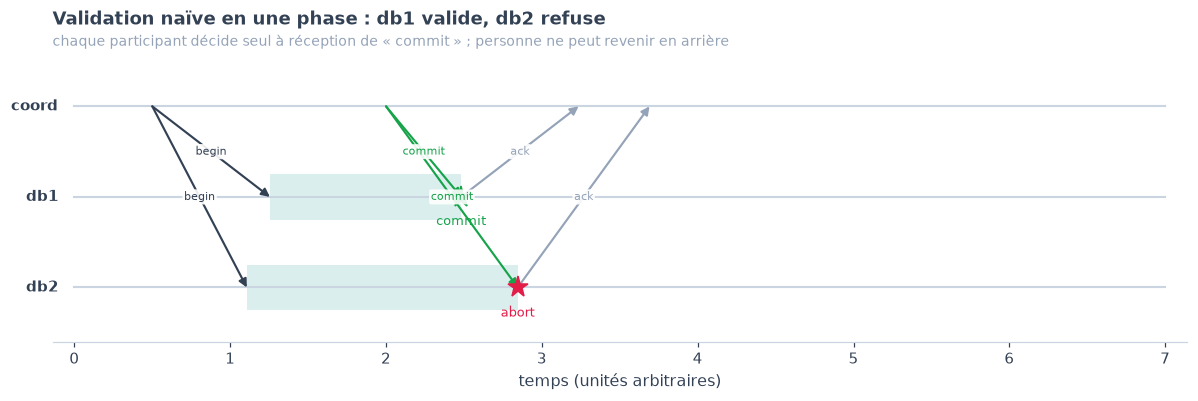

,participant,vote,issue
0,db1,yes,commit
1,db2,no,abort


In [2]:
naif = run_2pc(protocol="1pc", votes=["yes", "no"], t_max=7)
frise(naif, "Validation naïve en une phase : db1 valide, db2 refuse",
      "chaque participant décide seul à réception de « commit » ; personne ne peut revenir en arrière").show()
naif.summary[["participant", "vote", "issue"]]

db1 a validé, db2 a annulé : la transaction est **à moitié faite**, et l'atomicité est
perdue. Il faut que tous les participants valident, ou que tous annulent : c'est le
problème de la **validation atomique** (*atomic commitment*).

> **À retenir.** Sur un nœud, un seul disque prend la décision. Sur plusieurs nœuds,
> chacun peut échouer indépendamment : il faut un protocole pour que tous décident la
> même chose.

## 2. Le protocole de validation à deux phases (section *Introduction to two-phase commit*)

La **validation à deux phases** (2PC) est l'algorithme classique de validation atomique
entre plusieurs nœuds. Elle introduit un nouveau rôle, le **coordinateur** (ou
gestionnaire de transactions), souvent une bibliothèque dans le processus de
l'application (Narayana, JOTM, BTM, MSDTC...). Les nœuds de la base sont les
**participants**. Quand l'application veut valider :

- **phase 1** : le coordinateur envoie `prepare` à chaque participant, qui répond oui ou
  non ;
- **phase 2** : si tous ont dit oui, le coordinateur envoie `commit` ; sinon `abort`.

Le livre compare cela à une cérémonie de mariage : l'officier demande à chacun s'il
consent, et ne prononce l'union que si les deux ont dit oui.

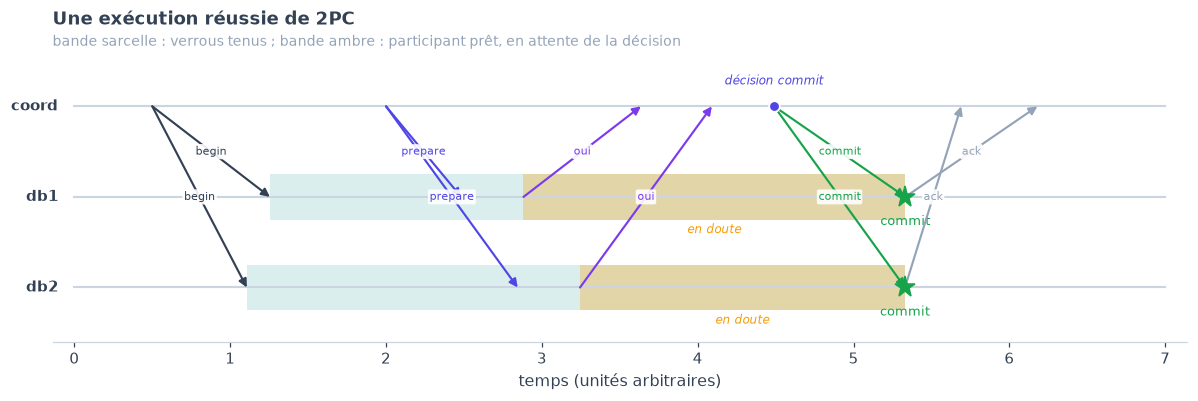

,participant,vote,issue,verrous_de,verrous_jusqu_à,durée_verrous,durée_en_doute
0,db1,yes,commit,1.25,5.33,4.08,2.45
1,db2,yes,commit,1.11,5.33,4.22,2.09


In [3]:
ok = run_2pc(t_max=7)
frise(ok, "Une exécution réussie de 2PC",
      "bande sarcelle : verrous tenus ; bande ambre : participant prêt, en attente de la décision").show()
ok.summary

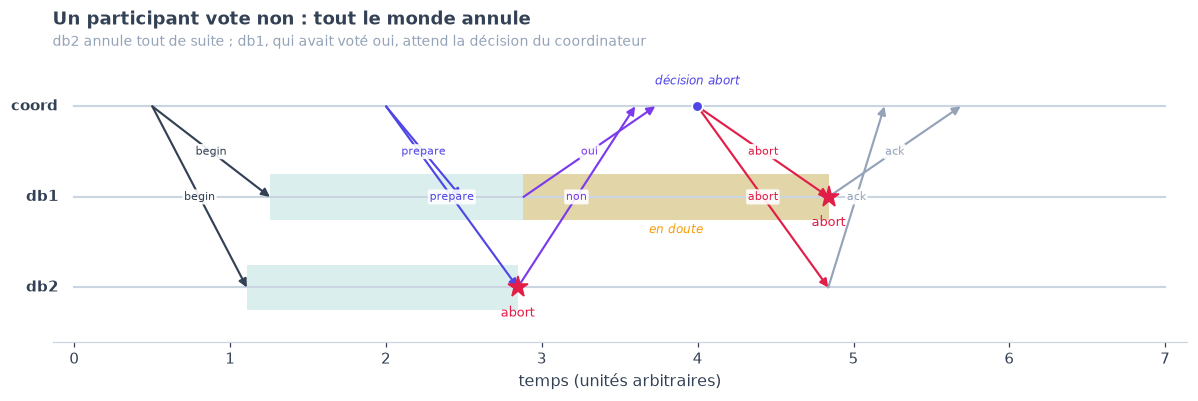

In [4]:
non = run_2pc(votes=["yes", "no"], t_max=7)
frise(non, "Un participant vote non : tout le monde annule",
      "db2 annule tout de suite ; db1, qui avait voté oui, attend la décision du coordinateur").show()

**Le coût.** Par rapport à une validation locale, 2PC ajoute deux allers-retours réseau
(préparation, décision) et des écritures durables (`fsync`) : chaque participant écrit
ses données et son vote avant de répondre oui, le coordinateur écrit sa décision avant de
la diffuser. Pour $n$ participants : $4n$ messages (dont $n$ accusés de réception
facultatifs pour la latence), $n + 1$ `fsync` sur le chemin critique, et des verrous
tenus pendant tout ce temps (bandes sarcelle). C'est une grande partie de la réputation
de lenteur des transactions distribuées.

> **À retenir.** 2PC sépare la validation en un vote (phase 1) et une décision (phase 2),
> prise par le coordinateur : commit seulement si tout le monde a voté oui.

## 3. Un système de promesses (section *A system of promises*)

Pourquoi 2PC est-il atomique alors que les messages peuvent se perdre aussi bien dans les
deux phases ? Parce qu'il contient **deux points de non-retour** :

1. quand un participant vote **oui**, il promet de pouvoir valider plus tard **quoi qu'il
   arrive** : il a écrit toutes les données sur disque et vérifié les contraintes ; il
   renonce à son droit d'annuler, sans pour autant valider ;
2. quand le coordinateur a reçu tous les votes, il **décide** et écrit sa décision dans
   son journal sur disque : c'est le **point de validation** (*commit point*). Ensuite, il
   renvoie la décision **indéfiniment** jusqu'à ce que chaque participant l'ait reçue ; un
   participant tombé en panne l'appliquera à son redémarrage.

Sur un seul nœud, ces deux événements sont confondus dans l'écriture du record de
validation. Le schéma résume les états du participant.

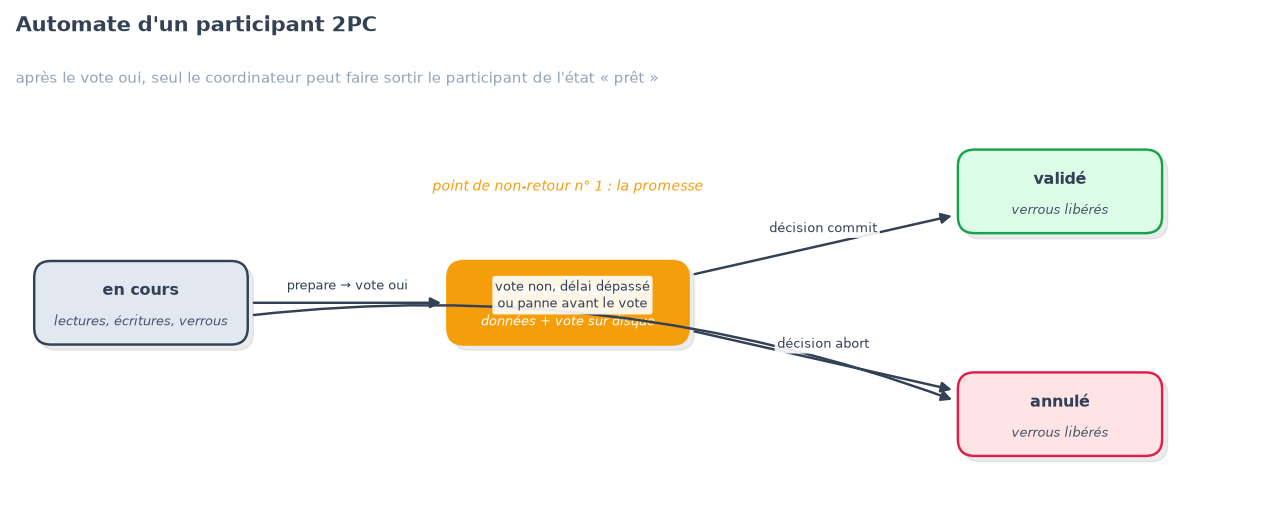

In [5]:
d = Diagram(13.5, 4.4, title="Automate d'un participant 2PC",
            subtitle="après le vote oui, seul le coordinateur peut faire sortir le participant de l'état « prêt »")
d.box("travail", 1.4, 2.2, "en cours", sub="lectures, écritures, verrous", color=SLATE, w=2.3)
d.box("pret", 6.0, 2.2, "prêt (en doute)", sub="données + vote sur disque", color=AMBER, w=2.6, filled=True)
d.box("commit", 11.3, 3.4, "validé", sub="verrous libérés", color=GREEN, w=2.2)
d.box("abort", 11.3, 1.0, "annulé", sub="verrous libérés", color=ROSE, w=2.2)
d.arrow("travail", "pret", "prepare → vote oui")
d.arrow("pret", "commit", "décision commit")
d.arrow("pret", "abort", "décision abort")
d.arrow("travail", "abort", "vote non, délai dépassé\nou panne avant le vote", rad=-0.12, label_pos=0.45)
d.note(6.0, 3.45, "point de non-retour n° 1 : la promesse", color=AMBER)
d.show()

**Vérification exhaustive.** Faisons tomber le coordinateur à **chaque instant** entre 0
et 8 (par pas de 0,05), avec redémarrage 10 unités plus tard, et regardons l'issue et la
durée pendant laquelle les participants restent en doute. Le coordinateur qui redémarre
relit son journal : s'il y trouve une décision, il la renvoie ; sinon, il annule
(**abandon présumé**).

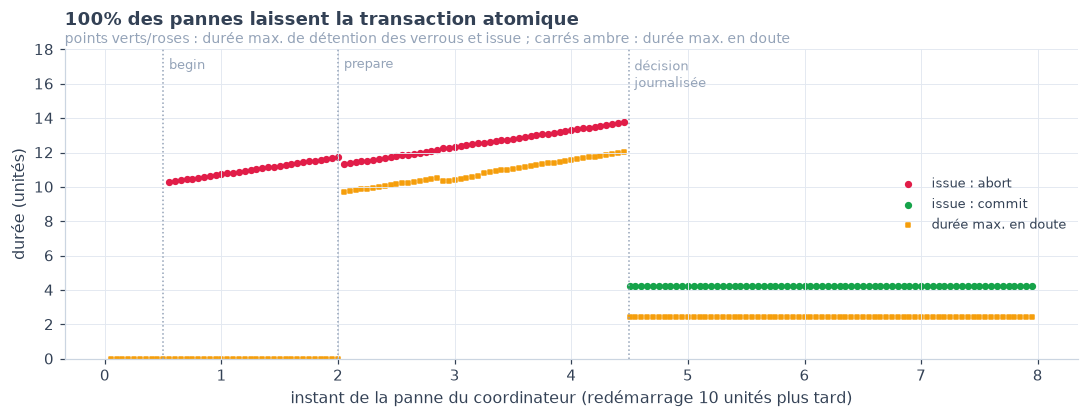

,min,max,count
issue,,,
abort,0.05,4.45,89
commit,4.50,7.95,70


In [6]:
instants = np.round(np.arange(0.05, 8.0, 0.05), 2)
lignes = []
for t in instants:
    r = run_2pc(crash={"coord": (t, t + 10)}, t_max=40)
    lignes.append(dict(t_panne=t, atomique=r.atomic, issue="/".join(sorted(set(r.summary["issue"]))),
                       doute_max=r.summary["durée_en_doute"].max(skipna=True),
                       verrous_max=r.summary["durée_verrous"].max()))
grille = pd.DataFrame(lignes).fillna({"doute_max": 0})
fig, ax = plt.subplots(figsize=(10, 3.9))
for issue, c in [("abort", ROSE), ("commit", GREEN)]:
    g_ = grille[grille["issue"] == issue]
    ax.scatter(g_["t_panne"], g_["verrous_max"], s=14, color=c, label=f"issue : {issue}")
ax.scatter(grille["t_panne"], grille["doute_max"], s=8, color=AMBER, marker="s", label="durée max. en doute")
for t, lab in [(0.5, "begin"), (2.0, "prepare"), (ok.coord.decided_at, "décision\njournalisée")]:
    ax.axvline(t, color=GRAY, ls=":", lw=1)
    ax.text(t + 0.05, 17.5, lab, fontsize=8.5, color=GRAY, va="top")
ax.set_xlabel("instant de la panne du coordinateur (redémarrage 10 unités plus tard)")
ax.set_ylabel("durée (unités)")
ax.set_ylim(0, 18)
ax.set_title(f"{grille['atomique'].mean():.0%} des pannes laissent la transaction atomique")
subtitle(ax, "points verts/roses : durée max. de détention des verrous et issue ; carrés ambre : durée max. en doute")
ax.legend(fontsize=8.5, loc="center right")
plt.tight_layout(); plt.show()
grille.groupby("issue")["t_panne"].agg(["min", "max", "count"])

Quel que soit l'instant de la panne, la transaction reste **atomique** (aucun mélange de
commit et d'abort) :

- panne **avant** l'écriture de la décision : au redémarrage, le journal ne contient pas
  de décision, le coordinateur annule ; les participants qui avaient voté oui restent en
  doute jusque-là (carrés ambre, de 10 à 12 unités) ; une panne avant `begin` n'a aucun
  effet visible (rien n'a commencé) ;
- panne **après** : la décision commit est dans le journal ; elle avait souvent déjà été
  reçue (pas de doute), sinon elle est renvoyée au redémarrage.

Le prix est visible sur l'axe vertical : pendant la panne, les verrous des participants
sont tenus jusqu'à 14 unités, contre environ 4 sans panne.

> **À retenir.** Deux promesses rendent 2PC atomique : le vote oui (je pourrai valider) et
> la décision journalisée (je la ferai appliquer, quoi qu'il arrive).